# PRT565 Assessment 4 — Breast Cancer Diagnosis Prediction
Group SYD-G1-22. Notebook adapted from the two supplied Assessment 3 Python scripts. Run cells in order. The first part reproduces the model workflow; the second reproduces the 12 report figures.

## Step 1 — Setup and imports

In [21]:
# Run once if the libraries are missing:
# %pip install numpy pandas matplotlib scikit-learn
import os, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, classification_report)
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
print('Ready: output folders created')

Ready: output folders created


## Step 2 — Load and inspect the data

In [22]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")      # 0 = malignant, 1 = benign

df = X.copy()
df["diagnosis"] = np.where(y == 0, "Malignant", "Benign")
df.to_csv(os.path.join(str(OUT), "breast_cancer_wisconsin.csv"), index=False)

print("Shape:", X.shape)
print("Missing values:", int(X.isnull().sum().sum()))
print("Duplicate rows:", int(X.duplicated().sum()))
print(y.map({0: "Malignant", 1: "Benign"}).value_counts())

Shape: (569, 30)
Missing values: 0
Duplicate rows: 0
target
Benign       357
Malignant    212
Name: count, dtype: int64


## Step 3 — Stratified 80/20 train-test split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

## Step 4 — Feature scaling (fit on training data only)

In [24]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Step 5 — Define the five models

In [25]:
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Naive Bayes": GaussianNB(),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=42),
    "ANN (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu",
                               solver="adam", early_stopping=True,
                               max_iter=1000, random_state=42),
}
uses_unscaled = {"Naive Bayes"}

## Step 6 — Train, predict and evaluate

In [26]:
rows, preds, probs = [], {}, {}
for name, model in models.items():
    Xtr, Xte = (X_train, X_test) if name in uses_unscaled else (X_train_s, X_test_s)
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1]
    preds[name], probs[name] = y_pred, y_prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })
    print(f"\n{name}\n", confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred,
                                target_names=["Malignant", "Benign"], digits=4))

results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)
results.to_csv(os.path.join(str(OUT), "model_results.csv"))


Decision Tree
 [[39  3]
 [ 6 66]]
              precision    recall  f1-score   support

   Malignant     0.8667    0.9286    0.8966        42
      Benign     0.9565    0.9167    0.9362        72

    accuracy                         0.9211       114
   macro avg     0.9116    0.9226    0.9164       114
weighted avg     0.9234    0.9211    0.9216       114


Random Forest
 [[39  3]
 [ 2 70]]
              precision    recall  f1-score   support

   Malignant     0.9512    0.9286    0.9398        42
      Benign     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114


Naive Bayes
 [[38  4]
 [ 3 69]]
              precision    recall  f1-score   support

   Malignant     0.9268    0.9048    0.9157        42
      Benign     0.9452    0.9583    0.9517        72

    accuracy                         0.9386       114
   macro avg     0.9360  

## Step 7 — Feature importance from the Random Forest

In [27]:
importances = pd.Series(models["Random Forest"].feature_importances_,
                        index=X.columns).sort_values(ascending=False)
print("\nTop 10 features:\n", importances.head(10).round(4))


Top 10 features:
 worst perimeter         0.1331
worst area              0.1281
worst concave points    0.1081
mean concave points     0.0944
worst radius            0.0906
mean radius             0.0587
mean perimeter          0.0552
mean area               0.0499
mean concavity          0.0462
worst concavity         0.0354
dtype: float64


## Report figures — from `analysis_and_charts.py`
These cells reproduce the original 12 charts. Each saved figure is also displayed below its cell. Note: descriptive PCA/scaling plots use the full dataset, as in the original script; the predictive models use training-only scaling.

### Chart setup

In [28]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#ffffff"
BEN, MAL = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Liberation Serif", "Times New Roman"],
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.dpi": 200,
    "legend.frameon": False,
})
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()
    plt.close()

d = load_breast_cancer()
X = pd.DataFrame(d.data, columns=d.feature_names); y = pd.Series(d.target)
lab = np.where(y == 0, "Malignant", "Benign")
stats = {}

### Figure 01 — class distribution

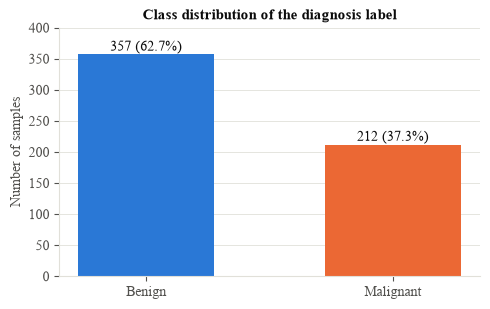

In [29]:
fig, ax = plt.subplots(figsize=(5, 3.2))
counts = [int((y == 1).sum()), int((y == 0).sum())]
bars = ax.bar(["Benign", "Malignant"], counts, color=[BEN, MAL], width=0.55)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width()/2, c + 6, f"{c} ({c/len(y):.1%})", ha="center", color=INK)
ax.set_ylabel("Number of samples"); ax.set_title("Class distribution of the diagnosis label")
ax.set_ylim(0, 400); ax.grid(axis="x", visible=False)
save("fig01_class_distribution.png")

### Figure 02 — correlation heatmap (30 features)

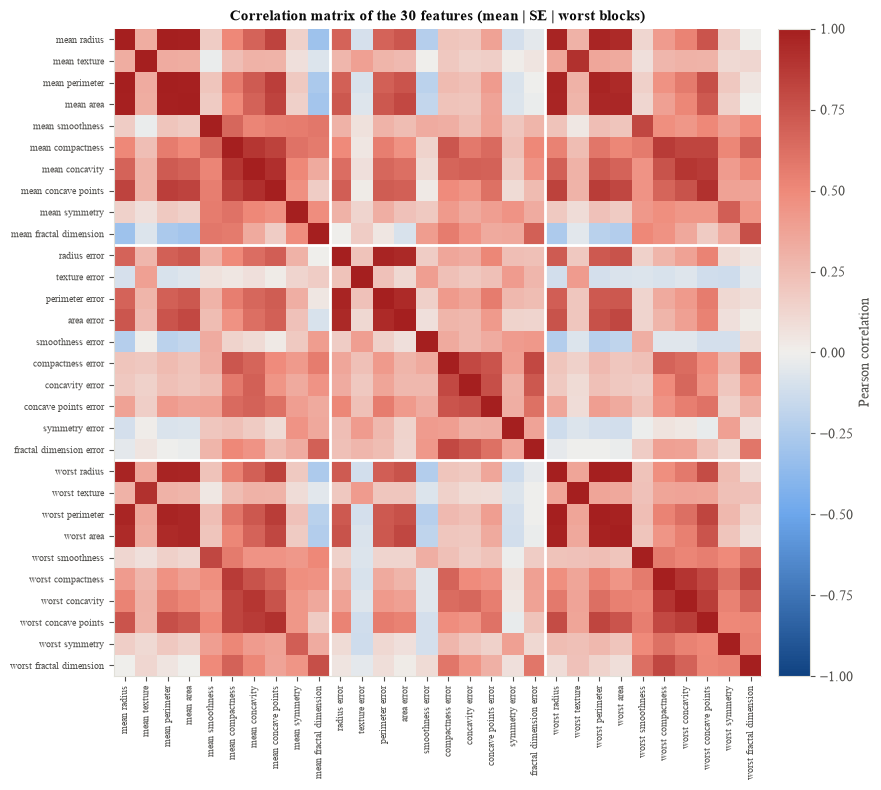

In [30]:
corr = X.corr()
cmap = LinearSegmentedColormap.from_list("div", ["#104281", "#6da7ec", "#f0efec", "#ef8a7a", "#a51f1f"])
fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(30)); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(30)); ax.set_yticklabels(corr.columns, fontsize=7)
ax.grid(False)
for v in [9.5, 19.5]:
    ax.axhline(v, color="white", lw=2); ax.axvline(v, color="white", lw=2)
cb = plt.colorbar(im, fraction=0.04, pad=0.02); cb.set_label("Pearson correlation")
ax.set_title("Correlation matrix of the 30 features (mean | SE | worst blocks)")
save("fig02_correlation_heatmap.png")
up = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
stats["n_pairs_above_0.9"] = int((up.abs() > 0.9).sum())
stats["top_pairs"] = {" ~ ".join(k): v for k, v in up.abs().sort_values(ascending=False).head(6).round(3).items()}
stats["corr_with_malignant"] = X.corrwith(1 - y).sort_values(ascending=False).round(3).to_dict()

### Figure 03 — distributions of key features by class

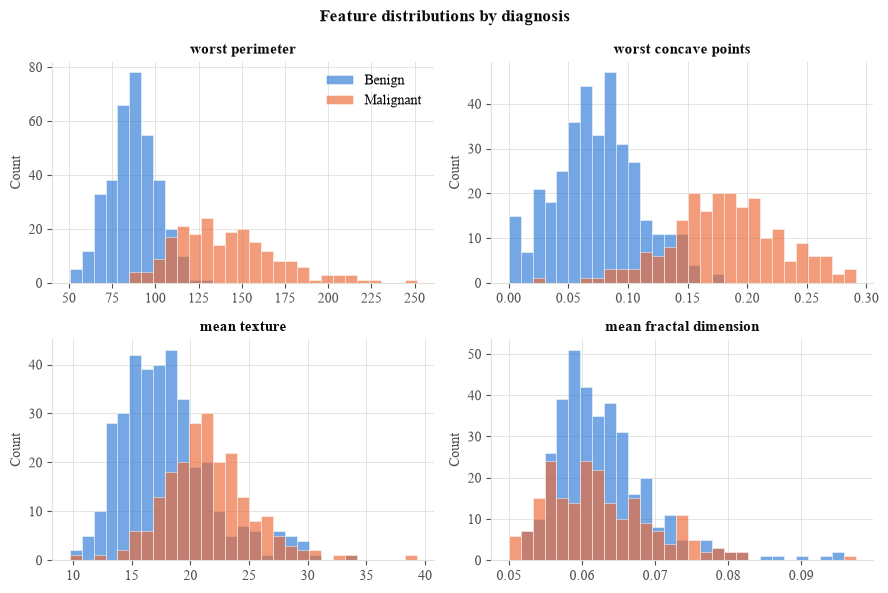

In [31]:
feats = ["worst perimeter", "worst concave points", "mean texture", "mean fractal dimension"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, f in zip(axes.ravel(), feats):
    bins = np.linspace(X[f].min(), X[f].max(), 30)
    ax.hist(X.loc[y == 1, f], bins=bins, color=BEN, alpha=0.65, label="Benign", edgecolor="white", linewidth=0.5)
    ax.hist(X.loc[y == 0, f], bins=bins, color=MAL, alpha=0.65, label="Malignant", edgecolor="white", linewidth=0.5)
    ax.set_title(f); ax.set_ylabel("Count")
axes[0, 0].legend()
fig.suptitle("Feature distributions by diagnosis", fontweight="bold", color=INK)
save("fig03_feature_distributions.png")

### Figure 04 — boxplots of standardised mean features

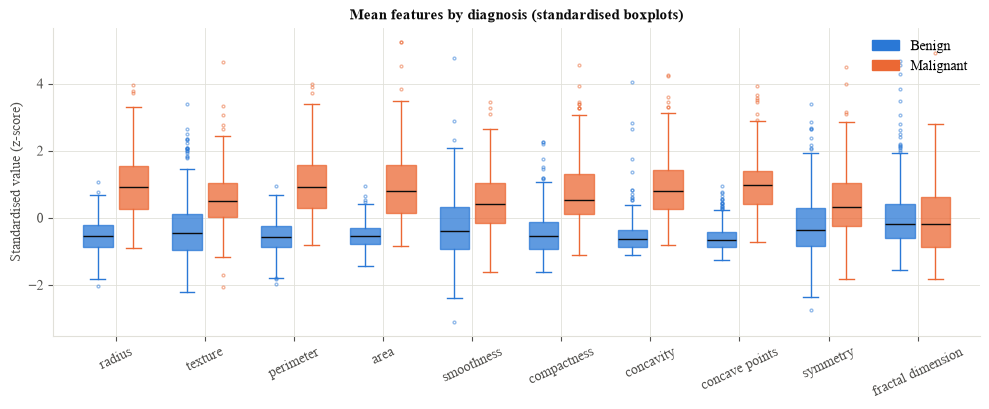

In [32]:
mean_cols = [c for c in X.columns if c.startswith("mean")]
Z = (X[mean_cols] - X[mean_cols].mean()) / X[mean_cols].std()
fig, ax = plt.subplots(figsize=(10, 4.2))
pos = np.arange(len(mean_cols))
for off, cls, col in [(-0.2, 1, BEN), (0.2, 0, MAL)]:
    bp = ax.boxplot([Z.loc[y == cls, c] for c in mean_cols], positions=pos + off, widths=0.33,
                    patch_artist=True, showfliers=True, flierprops=dict(marker="o", markersize=2, alpha=0.5, markeredgecolor=col),
                    medianprops=dict(color=INK, linewidth=1))
    for p in bp["boxes"]: p.set_facecolor(col); p.set_alpha(0.75); p.set_edgecolor(col)
    for k in ["whiskers", "caps"]:
        for l in bp[k]: l.set_color(col)
ax.set_xticks(pos); ax.set_xticklabels([c.replace("mean ", "") for c in mean_cols], rotation=25)
ax.set_ylabel("Standardised value (z-score)")
ax.legend([plt.Rectangle((0,0),1,1,color=BEN), plt.Rectangle((0,0),1,1,color=MAL)], ["Benign", "Malignant"], loc="upper right")
ax.set_title("Mean features by diagnosis (standardised boxplots)")
save("fig04_boxplots.png")

### Figure 05 — pairplot of 4 features

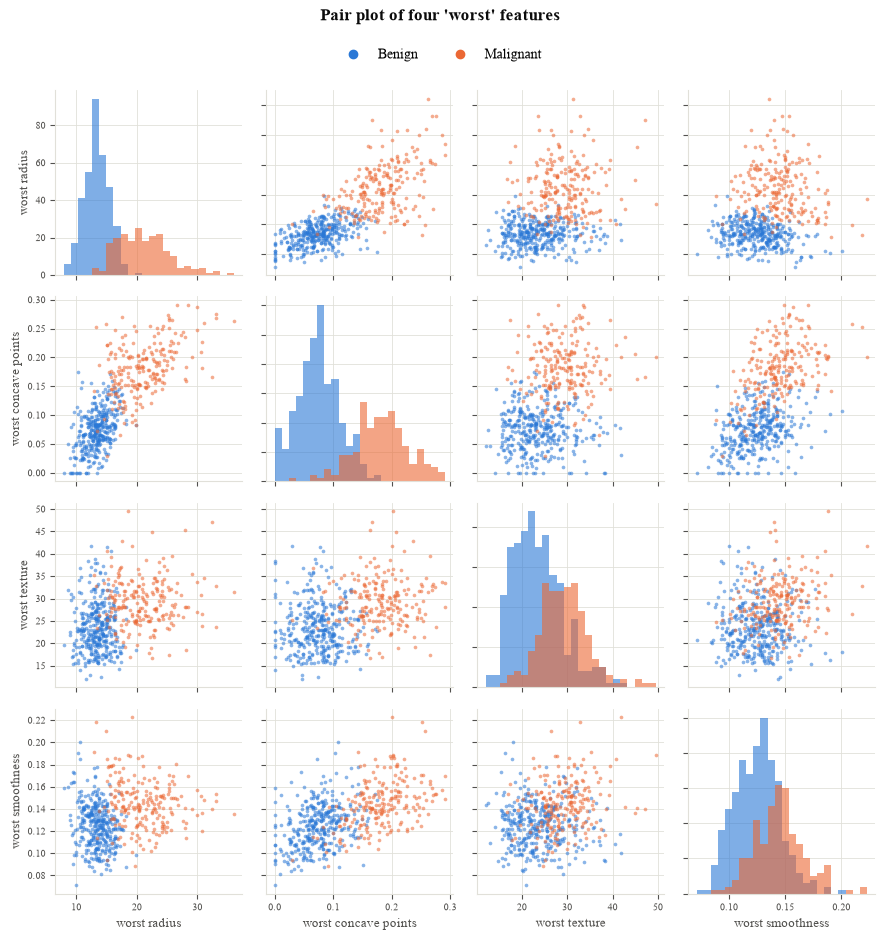

In [33]:
pf = ["worst radius", "worst concave points", "worst texture", "worst smoothness"]
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, a in enumerate(pf):
    for j, b in enumerate(pf):
        ax = axes[i, j]
        if i == j:
            bins = np.linspace(X[a].min(), X[a].max(), 25)
            ax.hist(X.loc[y == 1, a], bins=bins, color=BEN, alpha=0.6)
            ax.hist(X.loc[y == 0, a], bins=bins, color=MAL, alpha=0.6)
        else:
            ax.scatter(X.loc[y == 1, b], X.loc[y == 1, a], s=7, color=BEN, alpha=0.55, linewidths=0)
            ax.scatter(X.loc[y == 0, b], X.loc[y == 0, a], s=7, color=MAL, alpha=0.55, linewidths=0)
        if j == 0: ax.set_ylabel(a, fontsize=9)
        else: ax.set_yticklabels([])
        if i == 3: ax.set_xlabel(b, fontsize=9)
        else: ax.set_xticklabels([])
        ax.tick_params(labelsize=7)
fig.legend([plt.Line2D([], [], marker="o", ls="", color=BEN), plt.Line2D([], [], marker="o", ls="", color=MAL)],
           ["Benign", "Malignant"], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Pair plot of four 'worst' features", fontweight="bold", color=INK, y=1.04)
save("fig05_pairplot.png")

### Figure 06 — PCA

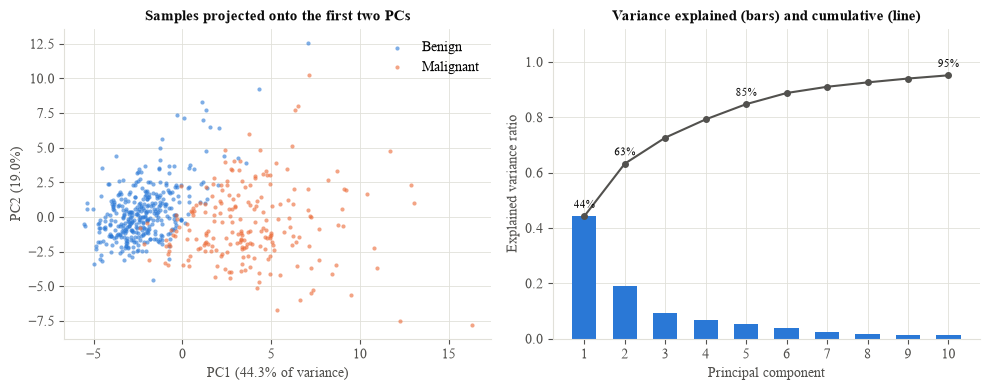

In [34]:
Xs_all = StandardScaler().fit_transform(X)
pca = PCA(n_components=10).fit(Xs_all); P = pca.transform(Xs_all)
stats["pca_var"] = pca.explained_variance_ratio_.round(4).tolist()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.scatter(P[y == 1, 0], P[y == 1, 1], s=9, color=BEN, alpha=0.6, label="Benign", linewidths=0)
ax.scatter(P[y == 0, 0], P[y == 0, 1], s=9, color=MAL, alpha=0.6, label="Malignant", linewidths=0)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"); ax.legend(); ax.set_title("Samples projected onto the first two PCs")
ax = axes[1]
cum = np.cumsum(pca.explained_variance_ratio_)
ax.bar(range(1, 11), pca.explained_variance_ratio_, color=BEN, width=0.6)
ax.plot(range(1, 11), cum, color=INK2, marker="o", lw=1.5, markersize=4)
for k in [0, 1, 4, 9]: ax.text(k + 1, cum[k] + 0.03, f"{cum[k]:.0%}", ha="center", fontsize=8, color=INK)
ax.set_ylim(0, 1.12); ax.set_xticks(range(1, 11)); ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio"); ax.set_title("Variance explained (bars) and cumulative (line)")
save("fig06_pca.png")

### Figure 07 — scaling effect

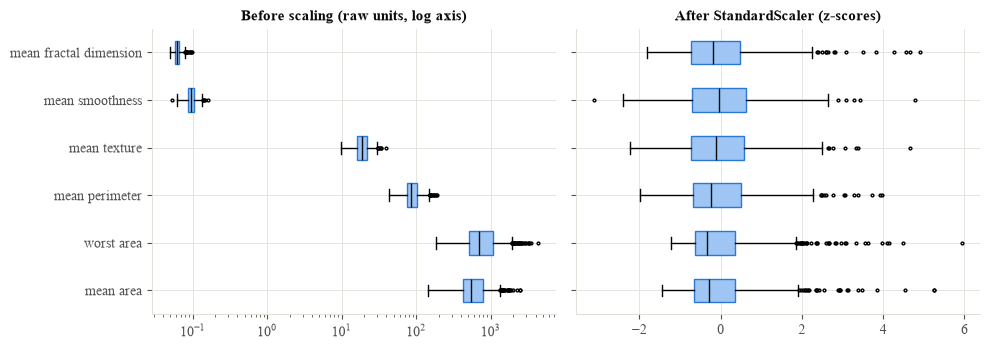

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sel = ["mean area", "worst area", "mean perimeter", "mean texture", "mean smoothness", "mean fractal dimension"]
axes[0].boxplot([X[c] for c in sel], vert=False, patch_artist=True, boxprops=dict(facecolor="#9ec5f4", edgecolor=BEN),
                medianprops=dict(color=INK), flierprops=dict(markersize=2))
axes[0].set_yticks(range(1, 7)); axes[0].set_yticklabels(sel); axes[0].set_xscale("log")
axes[0].set_title("Before scaling (raw units, log axis)")
Zs = StandardScaler().fit_transform(X[sel])
axes[1].boxplot([Zs[:, i] for i in range(6)], vert=False, patch_artist=True, boxprops=dict(facecolor="#9ec5f4", edgecolor=BEN),
                medianprops=dict(color=INK), flierprops=dict(markersize=2))
axes[1].set_yticks(range(1, 7)); axes[1].set_yticklabels([]); axes[1].set_title("After StandardScaler (z-scores)")
save("fig07_scaling.png")
stats["ranges"] = {c: [round(float(X[c].min()), 4), round(float(X[c].max()), 4)] for c in sel}
stats["skew_top"] = X.skew().sort_values(ascending=False).head(5).round(2).to_dict()

### Figure 08 — metric comparison

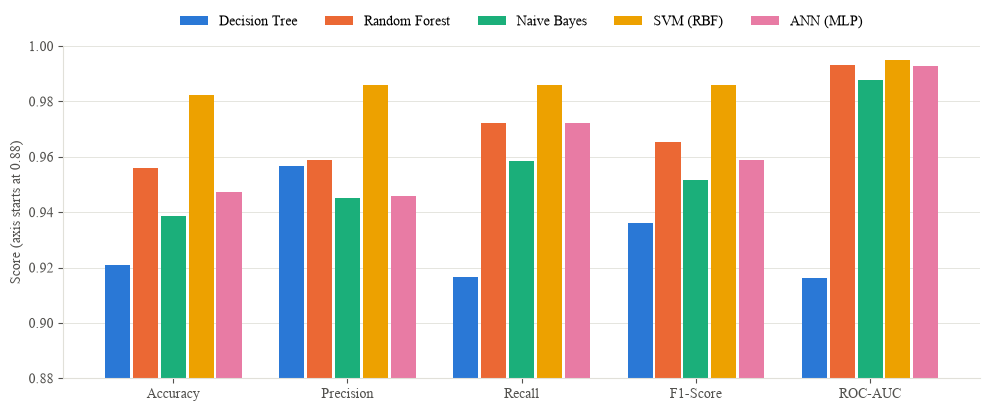

In [36]:
res = {name: {"Accuracy": accuracy_score(y_test, preds[name]), "Precision": precision_score(y_test, preds[name]), "Recall": recall_score(y_test, preds[name]), "F1": f1_score(y_test, preds[name]), "AUC": roc_auc_score(y_test, probs[name])} for name in models}
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
mets = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
fig, ax = plt.subplots(figsize=(10, 4.2))
w = 0.16; xpos = np.arange(len(mets))
for i, (n, c) in enumerate(zip(models, SERIES)):
    vals = [res[n][m] for m in mets]
    ax.bar(xpos + (i - 2) * w, vals, w * 0.9, color=c, label=n)
ax.set_xticks(xpos); ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])
ax.set_ylim(0.88, 1.0); ax.set_ylabel("Score (axis starts at 0.88)"); ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.13))
save("fig08_metric_comparison.png")

### Figure 09 — confusion matrices

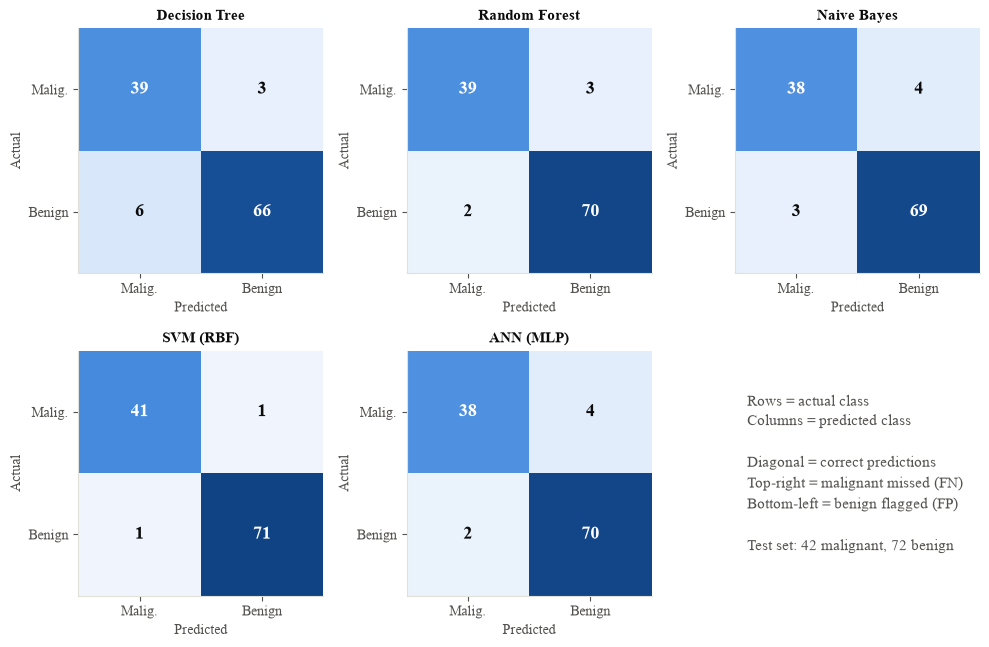

In [37]:
cms = {name: confusion_matrix(y_test, preds[name]).tolist() for name in models}
blues = LinearSegmentedColormap.from_list("seq", ["#f4f8fe", "#86b6ef", "#2a78d6", "#104281"])
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
axes = axes.ravel(); axes[5].axis("off")
axes[5].text(0.05, 0.5, "Rows = actual class\nColumns = predicted class\n\nDiagonal = correct predictions\nTop-right = malignant missed (FN)\nBottom-left = benign flagged (FP)\n\nTest set: 42 malignant, 72 benign",
             va="center", fontsize=11, color=INK2, linespacing=1.5)
for ax, n in zip(axes[:5], models):
    cm = np.array(cms[n]); ax.imshow(cm, cmap=blues, vmin=0, vmax=72); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if cm[i, j] > 30 else INK)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Malig.", "Benign"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Malig.", "Benign"])
    ax.set_title(n); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
save("fig09_confusion_matrices.png")

### Figure 10 — ROC

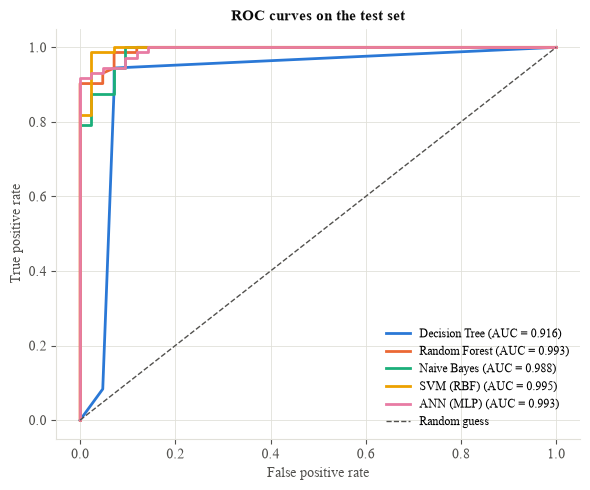

In [38]:
rocs = {name: roc_curve(y_test, probs[name]) for name in models}
fig, ax = plt.subplots(figsize=(6, 5))
for n, c in zip(models, SERIES):
    fpr, tpr, _ = rocs[n]; ax.plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC = {res[n]['AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=INK2, lw=1, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right", fontsize=8.5)
save("fig10_roc.png")

### Figure 11 — feature importance

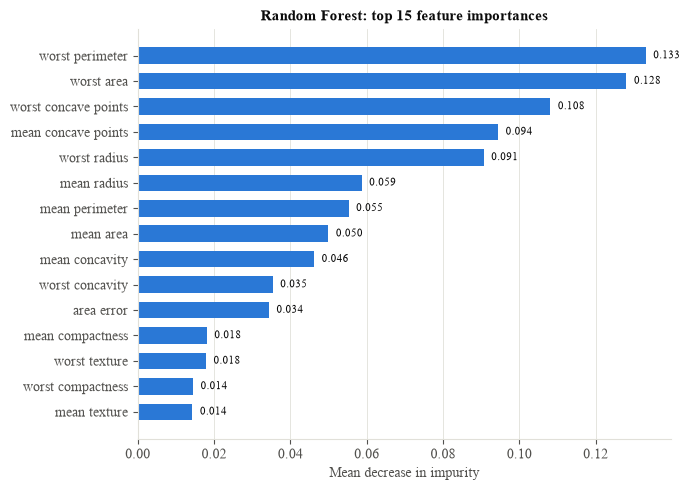

In [39]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
stats["importance_top10"] = imp.sort_values(ascending=False).head(10).round(4).to_dict()
stats["importance_by_group"] = {g: round(float(imp[[c for c in X.columns if c.startswith(g)]].sum()), 3) for g in ["mean", "worst"]}
stats["importance_by_group"]["error"] = round(float(imp[[c for c in X.columns if c.endswith("error")]].sum()), 3)
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=BEN, height=0.65)
for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
ax.set_xlabel("Mean decrease in impurity"); ax.set_title("Random Forest: top 15 feature importances"); ax.grid(axis="y", visible=False)
save("fig11_feature_importance.png")

### Figure 12 — decision tree (top 3 levels)

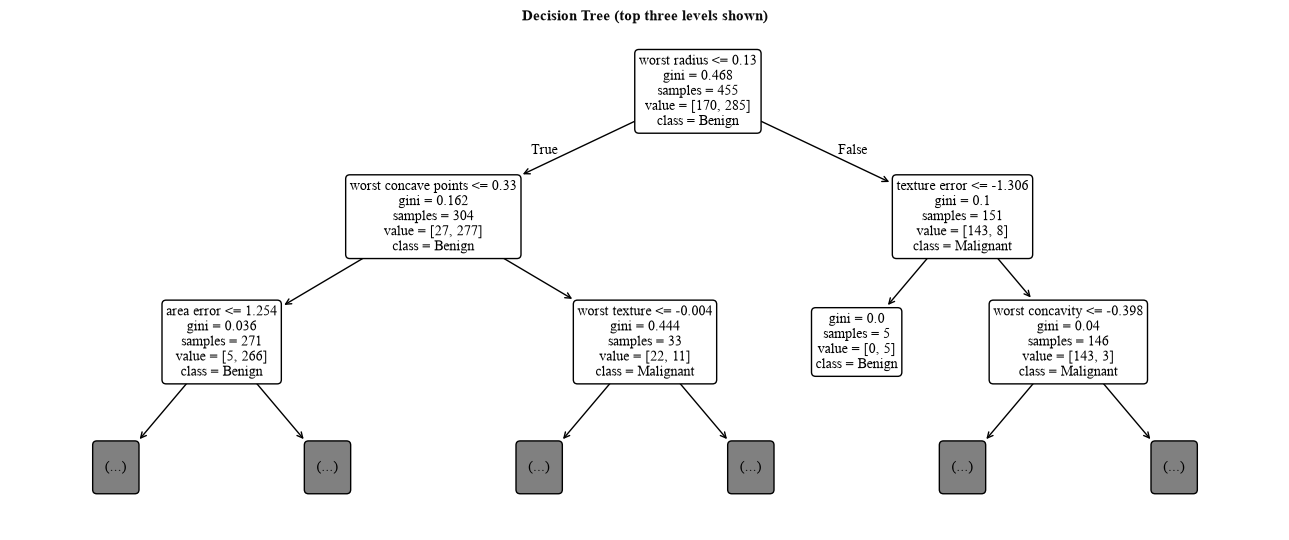

Saved all 12 figures to: C:\Users\kshet\OneDrive\Desktop\SYD-G1-22_Assessment4 (machine learning)\figures


In [40]:
fig, ax = plt.subplots(figsize=(13, 5.5))
plot_tree(models["Decision Tree"], max_depth=2, feature_names=X.columns, class_names=["Malignant", "Benign"],
          filled=False, rounded=True, fontsize=10, ax=ax, impurity=True)
ax.set_title("Decision Tree (top three levels shown)")
save("fig12_decision_tree.png")
tree = models["Decision Tree"].tree_
stats["dt_root"] = [X.columns[tree.feature[0]], round(float(tree.threshold[0]), 3)]


with open(FIG / 'stats.json', 'w') as f:
    json.dump(stats, f, indent=2, default=str)
print('Saved all 12 figures to:', FIG.resolve())